**Data Availability**

The original datasets are not included in this repository because they are provided by the educational platform and are subject to distribution restrictions.

The notebook contains the complete analysis workflow and all outputs.

# A/B-тест нового алгоритма рекомендаций

**Контекст.** Развлекательное приложение с «бесконечной» лентой коротких видео. Две модели монетизации: платная подписка без рекламы и показ рекламы пользователям без подписки.

Команда рекомендательных систем разработала новый алгоритм, который должен показывать каждому пользователю более интересный контент.

**Цель:** рассчитать параметры A/B-теста, проконтролировать корректность его проведения и оценить, повышает ли новый алгоритм вовлечённость пользователей.

**Целевая метрика:** доля успешных первых сессий — сессий, в которых пользователь просмотрел 4 и более страниц.

**Ожидаемый эффект:** рост метрики минимум на 3% относительно текущего уровня (около 30%).

## Описание данных

Данные — три таблицы с сессиями пользователей:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).
   

## Задачи
Рассчитать параметры теста, проверить корректность его проведения и проанализировать результаты эксперимента.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных и их проверка
Загрузим исторические данные о сессиях и проверим их качество: типы данных, пропуски, дубликаты и аномалии.

In [1]:
# Импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from math import ceil
from statsmodels.stats.proportion import proportions_ztest

In [2]:
# Выгружаем данные
sessions_history = pd.read_csv('datasets/sessions_project_history.csv')
sessions_test_part = pd.read_csv('datasets/sessions_project_test_part.csv')
sessions_test = pd.read_csv('datasets/sessions_project_test.csv')

Посмотрим первые пять строк и общую информацию по датафрейму `sessions_history`

In [3]:
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


In [4]:
sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            435924 non-null  object
 1   session_id         435924 non-null  object
 2   session_date       435924 non-null  object
 3   session_start_ts   435924 non-null  object
 4   install_date       435924 non-null  object
 5   session_number     435924 non-null  int64 
 6   registration_flag  435924 non-null  int64 
 7   page_counter       435924 non-null  int64 
 8   region             435924 non-null  object
 9   device             435924 non-null  object
dtypes: int64(3), object(7)
memory usage: 33.3+ MB


Судя по выводу, данные загрузились корректно, и в них нет явных пропусков (везде по `435 924 записи`).
Cтолбцы с датами (`session_date`, `session_start_ts`, `install_date`) сейчас имеют тип `object`. Чтобы с ними можно было работать как с датами (считать разницу во времени или фильтровать по периодам), приведем их к формату `datetime`:

In [5]:
sessions_history['session_date'] = pd.to_datetime(sessions_history['session_date'])
sessions_history['session_start_ts'] = pd.to_datetime(sessions_history['session_start_ts'])
sessions_history['install_date'] = pd.to_datetime(sessions_history['install_date'])

In [6]:
# Посмотрим уникальные значения в столбцах с типом object
for col in sessions_history.select_dtypes(include='object').columns:
    print(f"Уникальные значения в {col}:")
    print(sessions_history[col].unique())
    print("-" * 30)

Уникальные значения в user_id:
['E302123B7000BFE4' '2530F72E221829FB' '876E020A4FC512F5' ...
 '9608517F92C28B33' '3586AB0D05E4B6AC' 'B45B928ECA17147E']
------------------------------
Уникальные значения в session_id:
['F9AF61A0C2023832' '85003A206CBDAC6F' '3677423E49D72DEE' ...
 'C4CCD7E81733665F' '6834FB4914B56200' '8CC9E67AFF5D9CA8']
------------------------------
Уникальные значения в region:
['CIS' 'MENA' 'EU']
------------------------------
Уникальные значения в device:
['iPhone' 'Android' 'PC' 'Mac']
------------------------------


В ключевых категориальных столбцах неявных пропусков нет.

In [7]:
# Посчитаем дубликаты
sessions_history.duplicated().sum()

0

Изучим распределение данных и аномалии в числовых столбцах:

In [8]:
print(sessions_history.describe())

       session_number  registration_flag   page_counter
count   435924.000000      435924.000000  435924.000000
mean         2.382908           0.077325       3.005561
std          1.288487           0.267107       1.024625
min          1.000000           0.000000       1.000000
25%          1.000000           0.000000       2.000000
50%          2.000000           0.000000       3.000000
75%          3.000000           0.000000       4.000000
max         10.000000           1.000000       7.000000


Вывод по обзору данных:
- Пропуски и дубликаты: в датафрейме отсутствуют (435 924 корректные записи).
- Аномалии: в числовых столбцах (`page_counter`, `session_number`) выбросов не обнаружено.
- Типы данных: столбцы с датами (`session_date`, `session_start_ts`, `install_date`) приведены к формату `datetime`.
- Категории: в столбцах `region` и `device` представлены чистые уникальные значения без неявных пропусков.

#### 1.2. Знакомство с данными
Найдём пользователей с наибольшим числом сессий и изучим их историю, чтобы понять логику формирования столбцов.

In [9]:
# Считаем количество уникальных сессий для каждого пользователя
user_session_counts = sessions_history.groupby('user_id')['session_id'].nunique()

# Находим максимальное значение сессий
max_sessions_value = user_session_counts.max()

# Выбираем всех пользователей с таким количеством сессий
top_users_list = user_session_counts[user_session_counts == max_sessions_value]

print(f"Количество пользователей с максимумом сессий ({max_sessions_value}): {len(top_users_list)}")
print(top_users_list)

Количество пользователей с максимумом сессий (10): 2
user_id
10E0DEFC1ABDBBE0    10
6A73CB5566BB494D    10
Name: session_id, dtype: int64


In [10]:
# Посмотрим на сессии первого "максимального" пользователя
display(sessions_history[sessions_history['user_id'] == '10E0DEFC1ABDBBE0'].sort_values(by='session_number'))

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


- Номера сессий (`session_number`) идут строго по порядку и соответствуют времени старта (`session_start_ts`).
- Пользователь совершил все 10 сессий без регистрации (`registration_flag` везде равен 0). Это говорит о том, что он активно пользуется приложением в гостевом режиме.
- Пользователь заходит в приложение регулярно (с 14 по 25 августа), пропуская лишь отдельные дни.
- Установка была совершена с устройства на `Android` в регионе `CIS`. 
Количество просмотренных страниц (`page_counter`) стабильно и составляет от 1 до 4 за сессию.

In [11]:
# Посмотрим на сессии второго "максимального" пользователя
display(sessions_history[sessions_history['user_id'] == '6A73CB5566BB494D'].sort_values(by='session_number'))

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
124515,6A73CB5566BB494D,110E3F28C1F5415F,2025-08-28,2025-08-28 18:58:19,2025-08-28,1,0,3,MENA,Mac
196252,6A73CB5566BB494D,D68C8D98A0F1C439,2025-08-29,2025-08-29 20:53:27,2025-08-28,2,1,3,MENA,Mac
242428,6A73CB5566BB494D,6587D217472BF807,2025-08-30,2025-08-30 13:08:22,2025-08-28,3,1,1,MENA,Mac
304287,6A73CB5566BB494D,A9BC25593D056F8E,2025-09-01,2025-09-01 18:52:49,2025-08-28,4,1,2,MENA,Mac
346611,6A73CB5566BB494D,CB6F9C4191FAF6F6,2025-09-03,2025-09-03 22:49:08,2025-08-28,5,1,3,MENA,Mac
363510,6A73CB5566BB494D,9C609432F6E6535A,2025-09-04,2025-09-04 13:59:46,2025-08-28,6,1,4,MENA,Mac
391902,6A73CB5566BB494D,5D892E33B97A257A,2025-09-06,2025-09-06 18:46:55,2025-08-28,7,1,2,MENA,Mac
404322,6A73CB5566BB494D,22A9BD3861F49087,2025-09-07,2025-09-07 18:33:49,2025-08-28,8,1,3,MENA,Mac
415489,6A73CB5566BB494D,F70E351154B092DC,2025-09-08,2025-09-08 20:30:22,2025-08-28,9,1,4,MENA,Mac
425805,6A73CB5566BB494D,84A3DC0CFF449F53,2025-09-09,2025-09-09 16:36:04,2025-08-28,10,1,1,MENA,Mac


- Видно, что пользователь зарегистрировался во время второй сессии — именно тогда `registration_flag` изменился с 0 на 1 и далее оставался таким.
Поля `install_date`, `region` и `device` не меняются на протяжении всей истории, что подтверждает корректность склейки данных по `ID`.
- Пользователь заходит в приложение регулярно (почти каждый день), просматривая в среднем по 2-3 страницы за раз.

#### 1.3. Анализ числа зарегистрированных пользователей
Посмотрим, как по дням менялись общее число активных пользователей и число зарегистрированных среди них, а также их доля.

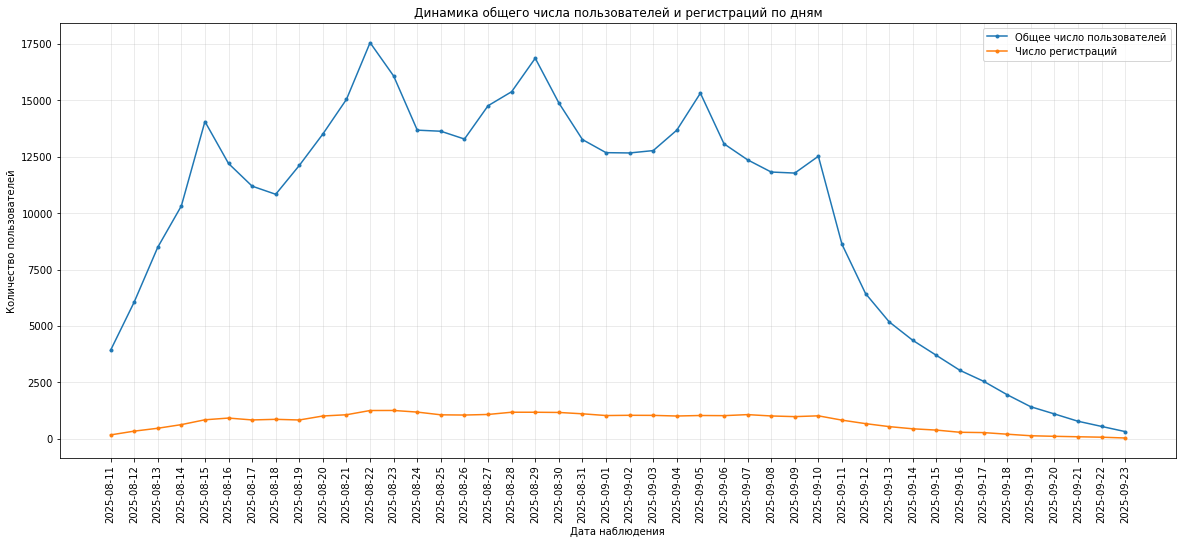

In [12]:
# Группируем данные
daily_data = sessions_history.groupby('session_date').agg(
    total_users=('user_id', 'nunique'),
    reg_users=('registration_flag', 'sum')
).reset_index()

plt.figure(figsize=(20, 8))

plt.plot(daily_data['session_date'], daily_data['total_users'], label='Общее число пользователей', marker='.')
plt.plot(daily_data['session_date'], daily_data['reg_users'], label='Число регистраций', marker='.')

# Указываем все даты и разворачиваем их на 90 градусов для читаемости
plt.xticks(daily_data['session_date'], rotation=90) 

plt.title('Динамика общего числа пользователей и регистраций по дням')
plt.xlabel('Дата наблюдения')
plt.ylabel('Количество пользователей')
plt.grid(True, alpha=0.3) # Делаем сетку чуть бледнее
plt.legend()
plt.show()


- В начале периода дневная аудитория составляла около 4 тыс. пользователей.
- Далее наблюдался быстрый рост, пик достигнут 22 августа — около 17.5 тыс. пользователей.
- После начала сентября показатель держался в диапазоне 12–15 тыс., затем с 11 сентября началось устойчивое снижение.
- К концу периода дневная аудитория снизилась до 300–500 пользователей.
- Число зарегистрированных среди активных пользователей было заметно стабильнее общего трафика.
- В августе и начале сентября — 900–1300 зарегистрированных пользователей в день.
- После середины сентября началось постепенное снижение, к концу периода — почти до нуля.
- Основную часть дневной аудитории составляют незарегистрированные пользователи.

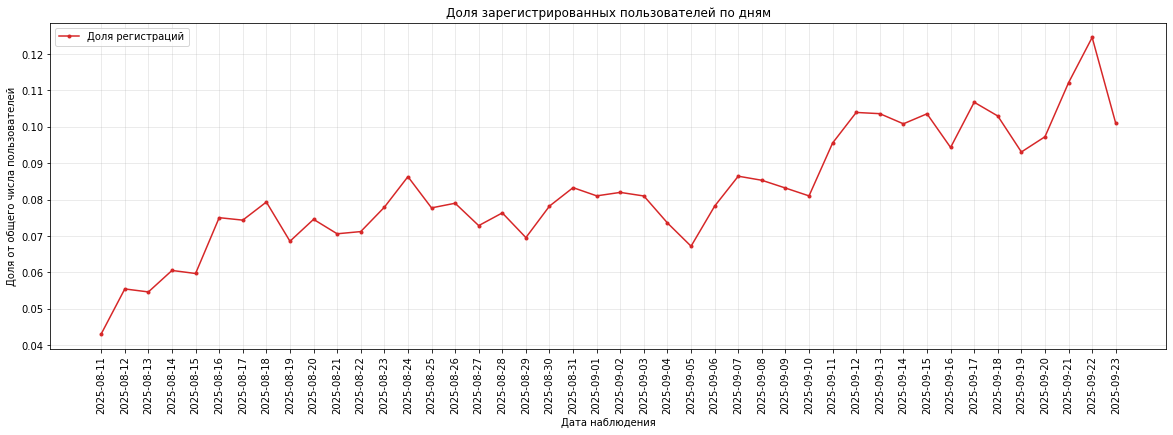

In [13]:
# Рассчитываем долю зарегистрированных пользователей
daily_data['reg_share'] = daily_data['reg_users'] / daily_data['total_users']

plt.figure(figsize=(20, 6))

plt.plot(daily_data['session_date'], daily_data['reg_share'], label='Доля регистраций', color='tab:red', marker='.')

# Указываем все даты и разворачиваем их на 90 градусов для читаемости
plt.xticks(daily_data['session_date'], rotation=90)

plt.title('Доля зарегистрированных пользователей по дням')
plt.xlabel('Дата наблюдения')
plt.ylabel('Доля от общего числа пользователей')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


- В начале периода доля регистраций составляла около 4.3%.
- В августе показатель вырос до 7–8%.
- В начале сентября держался на уровне 8–9%.
- Во второй половине сентября доля выросла до 10–12%.
- Максимальное значение зафиксировано 22 сентября — около 12.5%.
- Несмотря на снижение общего трафика, доля зарегистрированных росла.

В исторических данных видно **снижение общего пользовательского трафика после начала сентября**. При этом **регистрации снижались медленнее**, чем общий DAU.
**Доля** зарегистрированных выросла **с 4% до 10–12%**.
Рост доли происходит на фоне падения общего трафика: вероятно, незарегистрированные пользователи уходят быстрее зарегистрированных. Поэтому рост доли не обязательно означает рост конверсии в регистрацию. Кроме того, к концу периода наблюдений становится меньше, и колебания доли сильнее.

#### 1.4. Анализ числа просмотренных страниц
Число просмотренных страниц отражает вовлечённость пользователя: чем больше страниц, тем выше шансы на регистрацию и подписку. Посмотрим распределение этого показателя в первых сессиях.

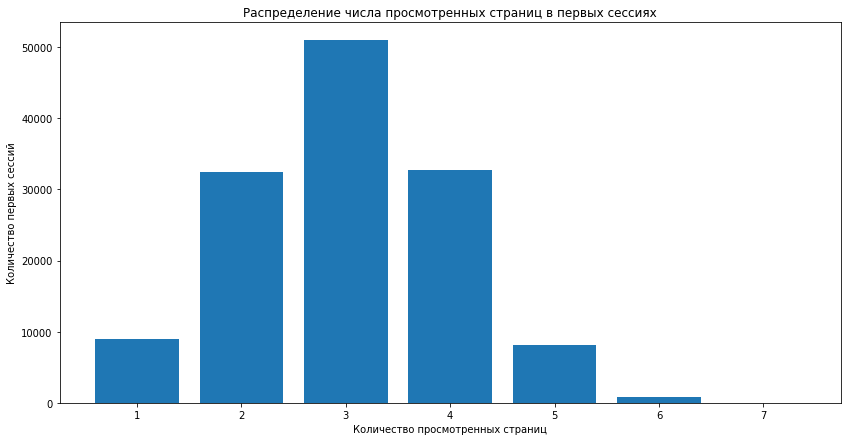

In [14]:
# Оставляем только первые сессии пользователей
first_sessions = sessions_history[sessions_history['session_number'] == 1]

# Считаем количество первых сессий для каждого числа просмотренных страниц
page_data = first_sessions.groupby('page_counter').agg(
    sessions_count=('session_id', 'count')
).reset_index()

# Строим столбчатую диаграмму
plt.figure(figsize=(14, 7))

plt.bar(page_data['page_counter'], page_data['sessions_count'])

plt.title('Распределение числа просмотренных страниц в первых сессиях')
plt.xlabel('Количество просмотренных страниц')
plt.ylabel('Количество первых сессий')

plt.show()

In [15]:
# Выводим таблицу
display(page_data)

,page_counter,sessions_count
0,1,8978
1,2,32494
2,3,50939
3,4,32739
4,5,8075
5,6,777
6,7,37


- Наиболее частый сценарий первой сессии — просмотр 3 страниц. Таких сессий около 51 тыс.
- Также часто пользователи просматривают 2 и 4 страницы — примерно по 32–33 тыс. сессий на каждое значение.
- Просмотр только 1 страницы встречается заметно реже — около 9 тыс. сессий.
- После 4 страниц число сессий резко снижается:
  - 5 страниц — около 8 тыс.
  - 6 страниц — около 1 тыс.
  - 7 страниц — единичные случаи.

**Общий вывод**


Большинство пользователей в первую сессию просматривают от 2 до 4 страниц. Пик распределения приходится на 3 страницы, что можно считать типичным поведением нового пользователя. 
Длинные первые сессии (5+ страниц) встречаются редко.
Это может говорить о том, что основная часть новых пользователей быстро знакомится с продуктом и принимает решение — продолжать использование или завершить сессию.


**Первые 3–4 просмотра** контента **особенно важны** для удержания и регистрации пользователя.

#### 1.5. Доля успешных первых сессий
Первую сессию с 4 и более просмотренными страницами считаем успешной (`good_session`): это прокси-метрика удовлетворённости контентом и рекомендациями. Посмотрим её динамику по дням.

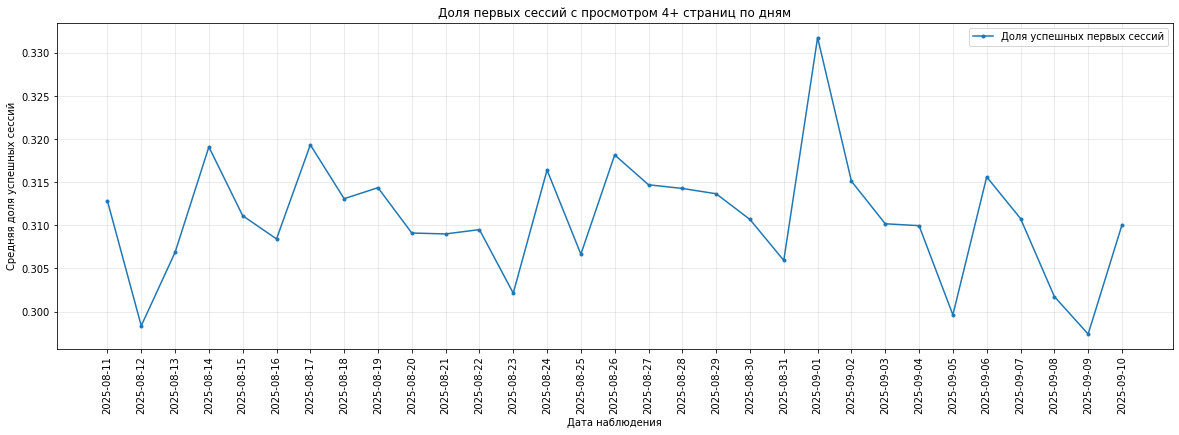

In [16]:
# Создаем признак успешной сессии
sessions_history['good_session'] = (sessions_history['page_counter'] >= 4).astype(int)

# Оставляем только первые сессии пользователей
first_sessions = sessions_history[sessions_history['session_number'] == 1]

# Считаем долю успешных первых сессий по дням
good_sessions_daily = first_sessions.groupby('session_date').agg(
    good_share=('good_session', 'mean')
).reset_index()

# Строим график
plt.figure(figsize=(20, 6))

plt.plot(
    good_sessions_daily['session_date'],
    good_sessions_daily['good_share'],
    marker='.',
    label='Доля успешных первых сессий'
)

plt.xticks(good_sessions_daily['session_date'], rotation=90)

plt.title('Доля первых сессий с просмотром 4+ страниц по дням')
plt.xlabel('Дата наблюдения')
plt.ylabel('Средняя доля успешных сессий')

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

In [17]:
# Выводим таблицу
display(good_sessions_daily)

,session_date,good_share
0,2025-08-11,0.312835
1,2025-08-12,0.298344
2,2025-08-13,0.306861
3,2025-08-14,0.319098
4,2025-08-15,0.311114
5,2025-08-16,0.308424
6,2025-08-17,0.319342
7,2025-08-18,0.313089
8,2025-08-19,0.314370
9,2025-08-20,0.309108


- Доля пользователей, просмотревших 4 и более страниц в первой сессии, на протяжении периода находилась в диапазоне 29.7%–33.2%.
- Среднее значение метрики — около 31%.
- Существенного восходящего или нисходящего тренда не наблюдается.
- Резкие отклонения отсутствуют, показатель меняется плавно в пределах узкого диапазона.
- Максимум зафиксирован 1 сентября — 33.18%.
- Минимум — 9 сентября — 29.74%.


**Общий вывод**


Примерно каждый третий новый пользователь проводит вовлечённую первую сессию.


**Метрика выглядит устойчивой во времени**, поэтому подходит как целевой показатель качества рекомендаций и удовлетворённости контентом.

На фоне такого ровного исторического поведения будет гораздо проще поймать и заметить реальные улучшения после запуска нового алгоритма.

### 2. Подготовка к тесту
На этапе планирования определим целевую метрику, рассчитаем необходимый размер выборки и длительность теста.

#### 2.1. Расчёт размера выборки
Параметры: уровень значимости α = 0.05, мощность 0.8 (β = 0.2), базовая доля успешных первых сессий ≈ 0.30, минимальный детектируемый эффект (MDE) — 3% относительно базового уровня.

In [18]:
# Параметры теста
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 1 - beta  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = p * 0.03  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### 2.2. Расчёт длительности A/B-теста
Разделим суммарный размер двух групп на средний дневной трафик приложения.

In [19]:
# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = sessions_history.groupby('session_date')['user_id'].nunique().mean()

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil(2 * sample_size / avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровне трафика в {avg_daily_users:.0f} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровне трафика в 9907 пользователей в день составит 9 дней


Средний дневной трафик приложения — около 9 907 пользователей. При размере выборки 41 040 пользователей на группу минимальная длительность теста — **9 дней**.

На практике тест лучше проводить не меньше 1–2 полных недель: поведение пользователей в будни и выходные различается, и слишком короткий тест может дать искажённый результат.

### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей
По данным первого дня теста проверим, что пользователи разделены на группы равномерно. Процентную разницу считаем по формуле:
$$P = 100 \cdot \frac{|A − B|}{A}$$

  test_group  users_count
0          A         1477
1          B         1466
Процентная разница между группами A и B: 0.74%


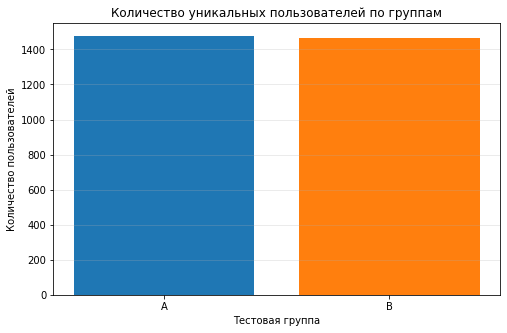

In [20]:
# Считаем уникальных пользователей по группам
group_users = sessions_test_part.groupby('test_group').agg(
    users_count=('user_id', 'nunique')
).reset_index()

print(group_users)

# Сохраняем значения
users_a = group_users.loc[group_users['test_group'] == 'A', 'users_count'].values[0]
users_b = group_users.loc[group_users['test_group'] == 'B', 'users_count'].values[0]

# Процентная разница
percent_diff = 100 * abs(users_a - users_b) / users_a

print(f'Процентная разница между группами A и B: {percent_diff:.2f}%')

# Визуализация
plt.figure(figsize=(8, 5))

plt.bar(
    group_users['test_group'],
    group_users['users_count'],
    color=['tab:blue', 'tab:orange']
)

plt.title('Количество уникальных пользователей по группам')
plt.xlabel('Тестовая группа')
plt.ylabel('Количество пользователей')

plt.grid(axis='y', alpha=0.3)

plt.show()

- Распределение пользователей между группами выглядит ровным и корректным.
- Отклонение менее 1% считается незначительным и не указывает на проблемы со сплитованием трафика.
- На старте эксперимента группы сопоставимы по размеру, значит тест технически запущен корректно.

#### 3.2. Проверка пересечений пользователей
Убедимся, что ни один пользователь не попал в обе группы одновременно.

In [21]:
# Создаем списки уникальных ID для каждой группы
users_a = sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id'].unique()
users_b = sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id'].unique()

# Находим пересечение (пользователей, которые попали в обе группы)
duplicates = set(users_a).intersection(set(users_b))

print(f"Количество пользователей в обеих группах: {len(duplicates)}")

if len(duplicates) > 0:
    print(f"Список ID с пересечениями: {list(duplicates)}")

Количество пользователей в обеих группах: 0


#### 3.3. Распределение пользователей по устройствам
Сравним доли типов устройств в группах A и B.

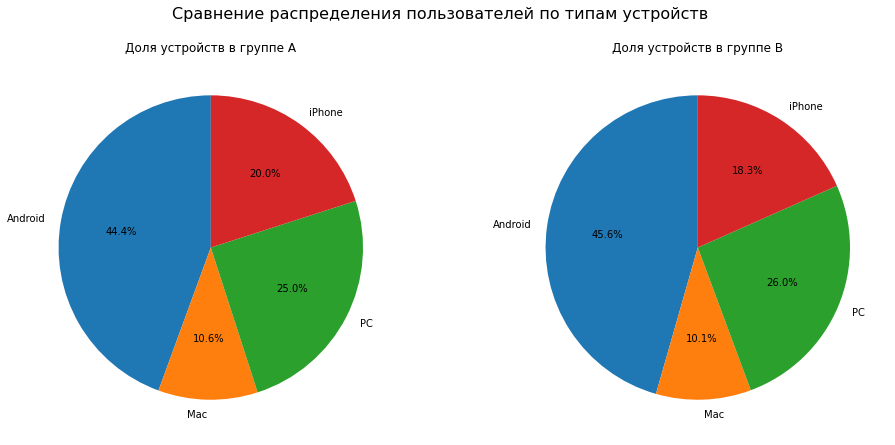

In [22]:
# Группируем данные по группе теста и устройству, считаем уникальных пользователей
device_stats = sessions_test_part.groupby(['test_group', 'device'])['user_id'].nunique().reset_index()

# Разделяем данные для удобства построения
data_a = device_stats[device_stats['test_group'] == 'A']
data_b = device_stats[device_stats['test_group'] == 'B']

# Строим диаграммы
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Группа A
ax1.pie(data_a['user_id'], labels=data_a['device'], autopct='%1.1f%%', startangle=90)
ax1.set_title('Доля устройств в группе A')

# Группа B
ax2.pie(data_b['user_id'], labels=data_b['device'], autopct='%1.1f%%', startangle=90)
ax2.set_title('Доля устройств в группе B')

plt.suptitle('Сравнение распределения пользователей по типам устройств', fontsize=16)
plt.show()


- Пользователи, одновременно попавшие в группы A и B, не обнаружены.


Группы являются независимыми, пересечения аудиторий отсутствуют.
Распределение пользователей выполнено корректно.
Результаты будущего сравнения между группами можно считать корректными с точки зрения структуры выборки.

- Существенного перекоса по устройствам между группами нет.


Структура аудиторий в группах A и B сопоставима.
Наибольшую долю пользователей в обеих группах занимает Android (около 45%), далее идут PC (около 25%), iPhone (19–20%) и Mac (около 10%).

#### 3.4. Распределение пользователей по регионам
Сравним доли регионов в группах A и B.

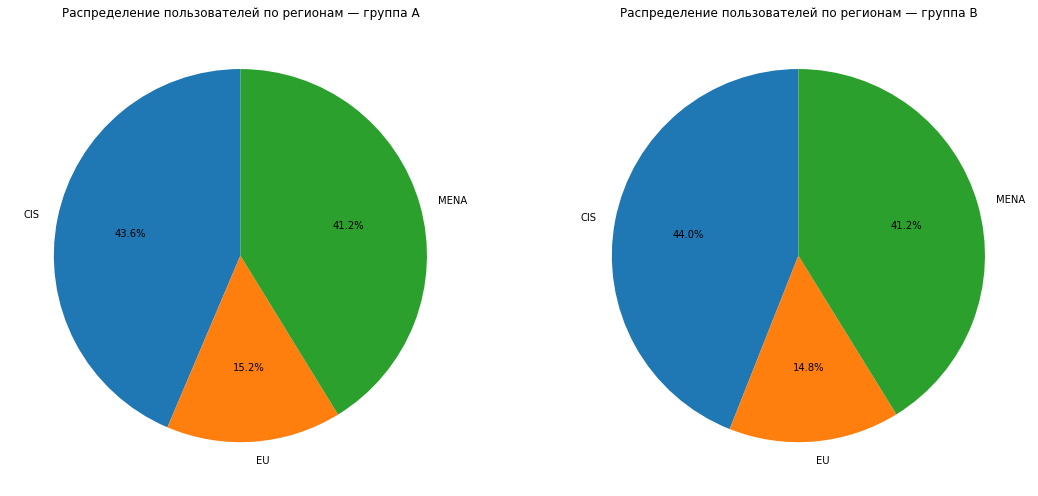

In [23]:
# Считаем количество уникальных пользователей по регионам и группам
region_data = sessions_test_part.groupby(['test_group', 'region']).agg(
    users_count=('user_id', 'nunique')
).reset_index()

# Считаем доли внутри каждой группы
region_data['share'] = region_data.groupby('test_group')['users_count'].transform(
    lambda x: x / x.sum()
)

# Отдельно данные по группам
region_a = region_data[region_data['test_group'] == 'A']
region_b = region_data[region_data['test_group'] == 'B']

# Строим диаграммы
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Группа A
axes[0].pie(
    region_a['share'],
    labels=region_a['region'],
    autopct='%1.1f%%',
    startangle=90
)
axes[0].set_title('Распределение пользователей по регионам — группа A')

# Группа B
axes[1].pie(
    region_b['share'],
    labels=region_b['region'],
    autopct='%1.1f%%',
    startangle=90
)
axes[1].set_title('Распределение пользователей по регионам — группа B')

plt.tight_layout()
plt.show()

- Существенных различий между группами по регионам нет.
- Аудитория в группах распределена равномерно и сбалансированно.
- Основную долю пользователей в обеих группах составляют регионы CIS и MENA — более 40% каждый.
- Пользователи из EU занимают меньшую долю — около 15%.



Так как распределение регионов между группами почти одинаковое, влияние географического фактора на результаты теста минимально.

#### 3.5. Вывод после проверки A/B-теста

В ходе мониторинга теста **существенных проблем** в распределении пользователей **не выявлено**.

Количество пользователей в группах практически одинаковое:
- группа A — 1477 пользователей
- группа B — 1466 пользователей
Процентная разница составляет 0.74%, что является незначительным отклонением.
- Выборки являются независимыми. Пересечений пользователей между группами A и B не обнаружено, один и тот же пользователь одновременно в две группы не попадал.
- Распределение пользователей по типам устройств между группами сохраняется равномерным. Существенных отклонений по долям Android, PC, iPhone и Mac не выявлено.
- Распределение пользователей по регионам также сбалансировано. Доли пользователей из CIS, MENA и EU в группах A и B практически совпадают.


A/B-тест проходит корректно. Критичных нарушений в разделение пользователей, пересечениях выборок или перекосах по категориальным признакам не обнаружено. Группы сопоставимы между собой, поэтому дальнейший анализ результатов эксперимента можно проводить корректно.

### 4. Проверка результатов A/B-теста

Тест завершён, доступны данные за весь период. Проверим результаты и интерпретируем их.

#### 4.1. Подсчёт основной метрики
Добавим в данные теста признак успешной сессии `good_session` (4 и более просмотренных страниц).

In [24]:
# Создаем признак успешной сессии
sessions_test['good_session'] = (
    sessions_test['page_counter'] >= 4
).astype(int)

# Проверяем результат
sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


#### 4.2. Гипотезы и метрики

Так как новый алгоритм рекомендаций должен показывать пользователям более интересный контент, основное ожидаемое изменение связано с ростом вовлечённости пользователей.

В рамках доступных данных **целевой метрикой** эксперимента выбрана доля успешных сессий (`good_session`) — сессий, в которых пользователь просмотрел 4 и более страниц.


**Нулевая гипотеза ($H_0$)**


Новый алгоритм рекомендаций не влияет на вовлечённость пользователей:


$H_0$: $p_A$ = $p_B$ 


Доля успешных сессий в группах A и B одинакова.


**Альтернативная гипотеза ($H_1$)**


Новый алгоритм рекомендаций увеличивает вовлечённость пользователей:

$H_1$: $p_B$ > $p_A$


Доля успешных сессий в тестовой группе B выше, чем в контрольной группе A.

**Возможные прокси-метрики** (позволяют быстрее заметить изменения):
- Среднее число просмотров за сессию.
- Длительность сессии: стали ли люди проводить в ленте больше времени.
- CTR рекомендаций: как часто пользователи кликают на то, что предлагает им новый алгоритм.
- D1 Retention: стали ли пользователи чаще возвращаться в приложение на следующий день.
- Число сессий на пользователя: стали ли люди заходить в приложение чаще в течение дня.


**Барьерные метрики** (показатели, которые не должны ухудшиться):
- выручка от рекламы и конверсия в платную подписку (алгоритм не должен мешать монетизации).
- crash rate (ошибки) и время загрузки ленты (тяжелый алгоритм не должен тормозить приложение).
- bounce rate (быстрые уходы) и количество жалоб или скрытий контента.


#### 4.3. Сравнение доли успешных первых сессий

In [25]:
# Оставляем только первые сессии пользователей
first_sessions = sessions_test[sessions_test['session_number'] == 1]

# Считаем долю успешных первых сессий и количество наблюдений по группам
test_results = first_sessions.groupby('test_group')['good_session'].agg(
    ['count', 'mean']
).reset_index()

test_results.columns = ['Группа', 'Всего первых сессий', 'Доля успешных']

# Извлекаем значения
share_a = test_results.loc[test_results['Группа'] == 'A', 'Доля успешных'].values[0]
share_b = test_results.loc[test_results['Группа'] == 'B', 'Доля успешных'].values[0]

# Разница
abs_diff = share_b - share_a

# Вывод
display(test_results)

print(f'Доля успешных первых сессий в группе A: {share_a:.2%}')
print(f'Доля успешных первых сессий в группе B: {share_b:.2%}')
print(f'Разница в долях: {abs_diff:+.4f}')

,Группа,Всего первых сессий,Доля успешных
0,A,15162,0.315724
1,B,15416,0.314673


Доля успешных первых сессий в группе A: 31.57%
Доля успешных первых сессий в группе B: 31.47%
Разница в долях: -0.0011


- Тестовая группа B не показала роста ключевой метрики относительно контрольной группы A.
- Напротив, значение метрики оказалось незначительно ниже (-0.11 п.п.), однако разница очень мала.
- На текущем этапе визуально эффект нового алгоритма отсутствует.


**Вывод**


Новый алгоритм рекомендаций не дал заметного улучшения доли успешных первых сессий.
Разница между группами находится в пределах естественных колебаний метрики.
Для окончательного решения необходимо провести проверку статистической значимости различий.

#### 4.4. Статистическая значимость изменения
Проверим значимость различия долей с помощью z-теста для пропорций (уровень значимости 0.05).

In [26]:
# Группировка данных по тестовым группам
stats = first_sessions.groupby('test_group')['good_session'].agg(
    ['sum', 'count']
).reset_index()

# Данные для z-теста
successes = stats['sum'].values
observations = stats['count'].values

# Z-test для сравнения долей
stat, p_value = proportions_ztest(
    count=successes,
    nobs=observations,
    alternative='smaller'
)

# Вывод p-value
print(f"p-value: {p_value:.4f}")

# Интерпретация результата
alpha = 0.05

if p_value < alpha:
    print("Различие статистически значимо. Нулевая гипотеза отвергается.")
else:
    print("Статистически значимых различий не обнаружено. Нет оснований отвергнуть нулевую гипотезу.")

p-value: 0.5784
Статистически значимых различий не обнаружено. Нет оснований отвергнуть нулевую гипотезу.


#### 4.5. Вывод по результатам A/B-эксперимента

**Вывод по результатам A/B-эксперимента**


Был проведён A/B-тест нового алгоритма рекомендаций, цель которого — проверить рост вовлечённости пользователей в первую сессию. В тесте участвовали:

- группа **A** (контрольная) — 15 162 пользователей;
- группа **B** (тестовая) — 15 416 пользователей.

Общая выборка составила **30 578 пользователей**.
Период проведения эксперимента: **с 14.10.2025 по 02.11.2025**.

**Результаты по ключевой метрике**

Ключевая метрика — доля успешных первых сессий (`good_session`), где пользователь просмотрел **4 и более страниц**.


Полученные результаты:

- группа **A — 31.57%**
- группа **B — 31.47%**

Изменение метрики составило **-0.11 п.п.** в тестовой группе относительно контрольной.


**Статистическая значимость**

По результатам z-теста:

- **p-value = 0.5784**

При уровне значимости **α = 0.05** статистически значимых различий между группами не обнаружено.


**Ограничения теста**

- Размер выборки рассчитывался на 41 040 пользователей в группе, а в тест попало около 15,2–15,4 тыс. новых пользователей на группу. Причина: длительность считалась по всему дневному трафику (около 9,9 тыс. пользователей), а целевая метрика строится только по первым сессиям новых пользователей.
- Из-за этого мощность теста для эффекта +3% оказалась около 50% вместо запланированных 80%: небольшое положительное влияние алгоритма тест мог не обнаружить.
- При этом наблюдаемая разница отрицательная (-0.11 п.п.), поэтому говорить о пользе нового алгоритма нет оснований.
- В следующих тестах длительность стоит рассчитывать по числу новых пользователей в день.

**Итоговое решение**


- Новый алгоритм не показал роста ключевой метрики. Значимого эффекта также не обнаружено.
- На текущем этапе внедрять решение на всех пользователей нецелесообразно.


**Рекомендации**
- проверить отдельные сегменты пользователей;
- доработать рекомендации;
- протестировать повторно;
- дополнительно посмотреть retention, регистрации и подписки.